In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

In [3]:
df =pd.read_csv('Diabetes.csv')
df

,PatientID,Pregnancies,PlasmaGlucose,DiastolicBloodPressure,TricepsThickness,SerumInsulin,BMI,DiabetesPedigree,Age,Diabetic
0,1354778,0,171,80,34,23,43.509726,1.213191,21,0
1,1147438,8,92,93,47,36,21.240576,0.158365,23,0
2,1640031,7,115,47,52,35,41.511523,0.079019,23,0
3,1883350,9,103,78,25,304,29.582192,1.282870,43,1
4,1424119,1,85,59,27,35,42.604536,0.549542,22,0
...,...,...,...,...,...,...,...,...,...,...
9995,1469198,6,95,85,37,267,18.497542,0.660240,31,0
9996,1432736,0,55,51,7,50,21.865341,0.086589,34,0
9997,1410962,5,99,59,47,67,30.774018,2.301594,43,1
9998,1958653,0,145,67,30,21,18.811861,0.789572,26,0


In [3]:
df.count()

PatientID                 10000
Pregnancies               10000
PlasmaGlucose             10000
DiastolicBloodPressure    10000
TricepsThickness          10000
SerumInsulin              10000
BMI                       10000
DiabetesPedigree          10000
Age                       10000
Diabetic                  10000
dtype: int64

In [4]:
df.describe()

,PatientID,Pregnancies,PlasmaGlucose,DiastolicBloodPressure,TricepsThickness,SerumInsulin,BMI,DiabetesPedigree,Age,Diabetic
count,1.000000e+04,10000.00000,10000.000000,10000.000000,10000.00000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000
mean,1.502122e+06,3.25580,107.850200,71.207500,28.81760,139.243600,31.567022,0.400944,30.134100,0.334400
std,2.892868e+05,3.40572,31.920909,16.801478,14.50648,133.777919,9.804366,0.381463,12.106047,0.471804
min,1.000038e+06,0.00000,44.000000,24.000000,7.00000,14.000000,18.200807,0.078044,21.000000,0.000000
25%,1.251672e+06,0.00000,84.000000,58.000000,15.00000,39.000000,21.247427,0.137065,22.000000,0.000000
50%,1.504394e+06,2.00000,105.000000,72.000000,31.00000,85.000000,31.922421,0.199698,24.000000,0.000000
75%,1.754608e+06,6.00000,129.000000,85.000000,41.00000,197.000000,39.328921,0.621158,35.000000,1.000000
max,1.999997e+06,14.00000,192.000000,117.000000,92.00000,796.000000,56.034628,2.301594,77.000000,1.000000


In [6]:
df.columns

Index(['PatientID', 'Pregnancies', 'PlasmaGlucose', 'DiastolicBloodPressure',
       'TricepsThickness', 'SerumInsulin', 'BMI', 'DiabetesPedigree', 'Age',
       'Diabetic'],
      dtype='object')

In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 10 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   PatientID               10000 non-null  int64  
 1   Pregnancies             10000 non-null  int64  
 2   PlasmaGlucose           10000 non-null  int64  
 3   DiastolicBloodPressure  10000 non-null  int64  
 4   TricepsThickness        10000 non-null  int64  
 5   SerumInsulin            10000 non-null  int64  
 6   BMI                     10000 non-null  float64
 7   DiabetesPedigree        10000 non-null  float64
 8   Age                     10000 non-null  int64  
 9   Diabetic                10000 non-null  int64  
dtypes: float64(2), int64(8)
memory usage: 781.4 KB


In [4]:
row_count =len(df)
row_count

10000

In [5]:
diabetic_count =df['Diabetic'].value_counts()
print(f'Diabetic Count:\n{diabetic_count}')

Diabetic Count:
Diabetic
0    6656
1    3344
Name: count, dtype: int64


In [ ]:
#Above dataset is slightly imbalanced dataset.
#plotting diabetic 

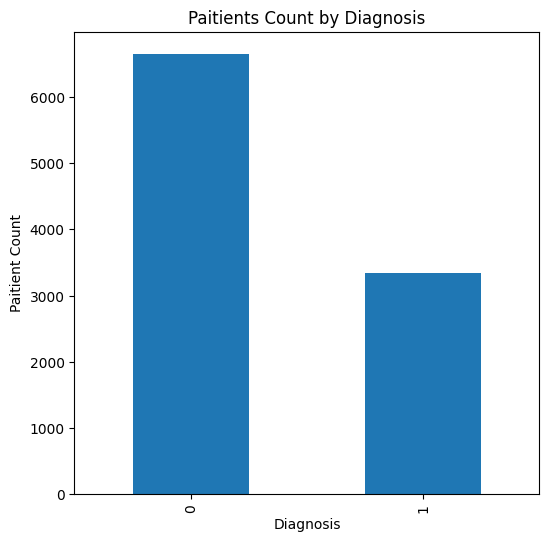

In [8]:
fig = plt.figure(figsize=(6,6))
axes = fig.gca()
diabetic_count.plot(kind='bar' ,ax=axes)
axes.set_title('Paitients Count by Diagnosis')
axes.set_xlabel('Diagnosis')
axes.set_ylabel('Paitient Count')
plt.savefig('random_forest_diabetic_count.png')
plt.show()

plt.close(fig)

In [9]:
import joblib
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix,classification_report 
from sklearn.ensemble import RandomForestClassifier

In [10]:
df.columns

Index(['PatientID', 'Pregnancies', 'PlasmaGlucose', 'DiastolicBloodPressure',
       'TricepsThickness', 'SerumInsulin', 'BMI', 'DiabetesPedigree', 'Age',
       'Diabetic'],
      dtype='object')

In [11]:
#Separating Features and Labels
x = df[[ 'Pregnancies', 'PlasmaGlucose', 'DiastolicBloodPressure',
       'TricepsThickness', 'SerumInsulin', 'BMI', 'DiabetesPedigree', 'Age',
       ]]
y = df['Diabetic']

In [12]:
x

,Pregnancies,PlasmaGlucose,DiastolicBloodPressure,TricepsThickness,SerumInsulin,BMI,DiabetesPedigree,Age
0,0,171,80,34,23,43.509726,1.213191,21
1,8,92,93,47,36,21.240576,0.158365,23
2,7,115,47,52,35,41.511523,0.079019,23
3,9,103,78,25,304,29.582192,1.282870,43
4,1,85,59,27,35,42.604536,0.549542,22
...,...,...,...,...,...,...,...,...
9995,6,95,85,37,267,18.497542,0.660240,31
9996,0,55,51,7,50,21.865341,0.086589,34
9997,5,99,59,47,67,30.774018,2.301594,43
9998,0,145,67,30,21,18.811861,0.789572,26


In [13]:
y

0       0
1       0
2       0
3       1
4       0
       ..
9995    0
9996    0
9997    1
9998    0
9999    0
Name: Diabetic, Length: 10000, dtype: int64

In [16]:
#split to train_test_split
x_train,x_test,y_train,y_test = train_test_split(x,y,test_size=0.3,random_state=42)

In [19]:
len(x_train)
type(y_train)

pandas.core.series.Series

In [20]:
diabetic_count = y_train.value_counts()
diabetic_count

Diabetic
0    4619
1    2381
Name: count, dtype: int64

In [27]:
# Train the RandomForestClassifier
model = RandomForestClassifier(n_estimators=200)
model

,n_estimators,200
,criterion,'gini'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [28]:
model.fit(x_train,y_train) # training the model

,n_estimators,200
,criterion,'gini'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [29]:
y_hat = model.predict(x_test)

In [30]:
print(confusion_matrix(y_test,y_hat))

[[1952   85]
 [ 121  842]]


In [41]:
print(classification_report(y_test,y_hat))

              precision    recall  f1-score   support

           0       0.94      0.96      0.95      2037
           1       0.91      0.87      0.89       963

    accuracy                           0.93      3000
   macro avg       0.92      0.92      0.92      3000
weighted avg       0.93      0.93      0.93      3000



In [42]:
#Prediction Inference
x_new = [[3,122, 79, 14, 298, 35.60456615, 1.55882579, 22],
         [10,100, 54, 34, 27, 38.84094285, 0.175464759, 23]]

predicted = model.predict(x_new)
actuals = [1, 0]
class_name = ['Non-Diabetic', 'Diabetic']
for i in range(len(predicted)):
          print(f'actual value  {class_name[actuals[i]]}')
          print(f'predicted value  {class_name[predicted[i]]}') 
          print('--'*20)
                 


actual value  Diabetic
predicted value  Diabetic
----------------------------------------
actual value  Non-Diabetic
predicted value  Non-Diabetic
----------------------------------------


C:\Ayesha\python\Machine-Learning\Ayesha-Practice\venv\Lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(


In [ ]:
#Visualization
#install graphviz software using https://graphviz.org/download
#install python package pydot(pip install pydot)
#install python package graphviz(pip install graphviz

In [44]:
%pip install pydot

Note: you may need to restart the kernel to use updated packages.


In [45]:
%pip install graphviz

Note: you may need to restart the kernel to use updated packages.


In [46]:
from sklearn.tree import export_graphviz
from six import StringIO
from IPython.display import Image
import pydot

In [47]:
x_train.columns

Index(['Pregnancies', 'PlasmaGlucose', 'DiastolicBloodPressure',
       'TricepsThickness', 'SerumInsulin', 'BMI', 'DiabetesPedigree', 'Age'],
      dtype='object')

In [48]:
#to know length of nested tree or collection of tree in the ensemble
len(model.estimators_)

200

In [61]:
dot_data =StringIO()
#export_graphviz(model, out_file=dot_data, feature_names= x_train.columns, filled=True, rounded=True, special_characters=True)
export_graphviz(model.estimators_[10], out_file=dot_data, feature_names= x_train.columns, rounded=True)
#export_graphviz(model, out_file=dot_data, feature_names= x_train.columns, rounded=True)



In [63]:
graph = pydot.graph_from_dot_data(dot_data.getvalue())
type(graph)

list

In [65]:
Image(graph[0].create_png())

SyntaxError: unmatched ')' (517900630.py, line 1)